### Import Libraries

In [1]:
import numpy as np                        # For matrix operations, array processing and mathematical calculations
import matplotlib.pyplot as plt           # Used for drawing convergence curves and box plots
from scipy.stats import mannwhitneyu      # Mann-Whitney U Non-parametric Hypothesis Test for Part 3
import random                             # Used to control the random number seed to ensure the reproducibility of the experiment
import time                               # Used to record the running time of the algorithm (Part 3's trade-off analysis)
import os                                 # Used for creating and manipulating folders

# Configure the Matplotlib font to ensure that Chinese characters in the chart can be displayed normally and negative signs are displayed correctly
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

### Shared Utility Functions
This cell contains reusable helper functions shared by both Variant A (Penalty) and Variant B (Repair).

In [4]:
# Shared Utility Functions

def load_workload_instance(file_path):
    """
    Load the multi-resource workload dataset from a text file.
    Returns: number of items (n), number of resources (m), 
             utilities array, demands matrix, and capacities array.
    """
    with open(file_path, 'r') as f:
        tokens = f.read().split()
    if not tokens:
        raise ValueError(f"Dataset file at '{file_path}' is empty or invalid.")

    # Parse the header: n (items) and m (resources)
    n = int(tokens[0]); m = int(tokens[1]); idx = 2
    
    # Parse the utilities (value) of each item
    utilities = np.array([float(x) for x in tokens[idx: idx + n]]); idx += n

    # Parse the demands matrix (shape: m x n)
    demands = np.zeros((m, n))
    for i in range(m):
        demands[i, :] = [float(x) for x in tokens[idx: idx + n]]
        idx += n

    # Parse the capacities of each resource
    capacities = np.array([float(x) for x in tokens[idx: idx + m]])
    return n, m, utilities, demands, capacities


def is_feasible(solution, demands, capacities, eps=1e-9):
    """
    Check if a binary solution satisfies all resource capacity constraints.
    The epsilon (1e-9) is used to handle floating-point numerical precision errors.
    """
    res_used = demands @ solution                    # Calculate actual usage for each resource
    return np.all(res_used <= capacities + eps)      # All resources must be within limits


# ---------- Variant A: Penalty ----------
def fitness_penalty(solution, utilities, demands, capacities, penalty_weight=10000):
    """
    Fitness function for Variant A (Penalty method).
    If feasible, returns the total utility. 
    If infeasible, subtracts a large penalty proportional to the resource overshoot.
    """
    total_u = float(utilities @ solution) # Calculate raw total utility
    
    if is_feasible(solution, demands, capacities):
        return total_u # Return raw utility if the solution is feasible
    
    # If infeasible, calculate the overshoot for each resource and apply a heavy penalty
    overshoot = np.maximum((demands @ solution) - capacities, 0.0)
    return total_u - penalty_weight * float(np.sum(overshoot))


# ---------- Variant B: Repair ----------
def repair_solution(sol, demands, capacities, utilities):
    """
    Repair strategy for Variant B: 
    For an infeasible solution, iteratively remove selected items in ascending order 
    of their utility-density (value / total resource consumption) until it becomes feasible.
    """
    sol = sol.copy().astype(int) # Copy the solution to avoid modifying the original
    n = len(sol)
    density = np.zeros(n)
    mask = sol == 1              # Identify currently selected items
    
    # Calculate utility-density for the selected items
    if mask.any():
        density[mask] = utilities[mask] / (demands[:, mask].sum(axis=0) + 1e-9)
        
    # Get indices of selected items and sort them by density in ascending order
    selected_idx = np.where(sol == 1)[0]
    selected_idx = selected_idx[np.argsort(density[selected_idx])]
    
    # Remove items one by one starting from the lowest density until the solution is feasible
    for idx in selected_idx:
        if is_feasible(sol, demands, capacities):
            break # Stop removing if the solution is already feasible
        sol[idx] = 0 # Remove the item
        
    return sol


def fitness_repair(sol, utilities, demands, capacities):
    """
    Fitness function for Variant B (Repair method).
    Repairs the solution first, then returns a tuple: (repaired_fitness, repaired_solution).
    """
    fixed_sol = repair_solution(sol, demands, capacities, utilities) # Force repair
    
    if is_feasible(fixed_sol, demands, capacities):
        # Return (utility of the repaired solution, repaired solution vector)
        return float(utilities @ fixed_sol), fixed_sol
        
    # Fallback in extreme edge cases where repair fails
    return 0.0, fixed_sol

## Task1: Hill Climb

==== Hill-Climber Results | Instance n=28 m=2 ====
Independent runs: 10
Iteration budget per run: 1500
Maximum fitness: 95205.00
Minimum fitness: 39012.00
Mean fitness:    73649.90
Std deviation:   16970.18


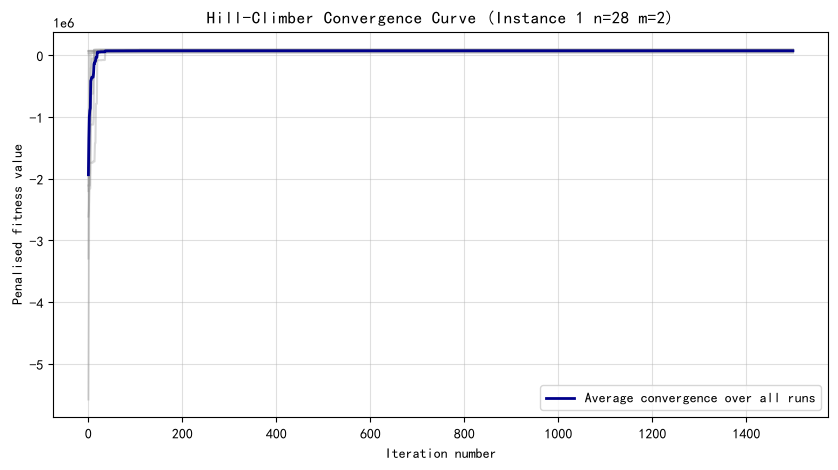

In [7]:
# ========== Part 1: Hill-Climber baseline (n=28, m=2) ==========

def hill_climber(n, utilities, demands, capacities, max_iter=1500, seed=42):
    """
    Discrete local search (hill-climber) algorithm.
    Uses single-bit flip as the mutation operator and a greedy acceptance rule.
    """
    rng = np.random.default_rng(seed)
    
    # Initialisation: generate a random binary solution
    current_sol = rng.integers(0, 2, size=n)
    current_fit = fitness_penalty(current_sol, utilities, demands, capacities)
    
    # Record the best solution found so far
    best_sol = current_sol.copy()
    best_fit = current_fit
    convergence_history = []
    
    for _ in range(max_iter):
        convergence_history.append(best_fit)
        
        # Variation: single-bit flip (Hamming distance = 1) to generate a neighbour
        neighbour = current_sol.copy()
        flip_pos = rng.integers(0, n)
        neighbour[flip_pos] = 1 - neighbour[flip_pos]
        
        # Evaluate the neighbour using the penalty-based fitness function
        neighbour_fit = fitness_penalty(neighbour, utilities, demands, capacities)
        
        # Acceptance rule: greedy hill-climbing (accept only if fitness strictly improves)
        if neighbour_fit > current_fit:
            current_sol = neighbour
            current_fit = neighbour_fit
            
            # Update the global best if the new solution is better
            if current_fit > best_fit:
                best_fit = current_fit
                best_sol = current_sol.copy()
                
    return best_sol, best_fit, convergence_history


# --- run Part 1 ---
# Load Instance 1 (n=28, m=2)
n1, m1, v1, W1, b1 = load_workload_instance("data/multi_resource_n28_m2.txt")

# Experimental parameters
num_runs = 10      # 10 independent runs
max_iter = 1500    # Iteration budget per run
all_best_fitness = []
all_convergence_histories = []

# Execute the 10 independent runs with distinct fixed seeds
for run_id in range(num_runs):
    best_s, best_fit, hist = hill_climber(n1, v1, W1, b1, max_iter=max_iter, seed=run_id)
    all_best_fitness.append(best_fit)
    all_convergence_histories.append(hist)

# Print statistical summary
print("==== Hill-Climber Results | Instance n=28 m=2 ====")
print(f"Independent runs: {num_runs}")
print(f"Iteration budget per run: {max_iter}")
print(f"Maximum fitness: {np.max(all_best_fitness):.2f}")
print(f"Minimum fitness: {np.min(all_best_fitness):.2f}")
print(f"Mean fitness:    {np.mean(all_best_fitness):.2f}")
print(f"Std deviation:   {np.std(all_best_fitness):.2f}")

# Plot convergence curve
plt.figure(figsize=(10, 5), dpi=100)

# Plot individual runs (grey lines) to show variance
for h in all_convergence_histories:
    plt.plot(h, c="gray", alpha=0.3)

# Plot the average convergence curve over all runs
mean_curve = np.mean(np.array(all_convergence_histories), axis=0)
plt.plot(mean_curve, c="darkblue", lw=2, label="Average convergence over all runs")

plt.title("Hill-Climber Convergence Curve (Instance 1 n=28 m=2)")
plt.xlabel("Iteration number")
plt.ylabel("Penalised fitness value")
plt.legend()
plt.grid(alpha=0.4)
plt.show()

### Numerical Results
As can be seen from the results, the standard deviation is 16970.18. This large standard deviation indicates that the optimal solutions obtained from the 10 experiments vary significantly; the hill-climbing algorithm exhibits high variability in its results for this example and has relatively poor stability.

### Plot
The figure shows the convergence process of the hill-climbing algorithm over 10 repeated experiments. The light gray lines represent the fitness changes for each individual run, while the dark blue solid line is the average convergence curve across the 10 runs.
During the initial phase of the iteration, fitness rises rapidly as the algorithm quickly optimizes the solution; however, the curve soon flattens out, with almost no further improvement. Thisshowss that the hill-climbing algorithm is prone to getting stuck in local optima, making it difficult to find better solutions in subsequent iterations—which is one reason for its unstable results.

## Task2: GA is undergoing independent verification

==== GA (Variant B) sanity check on n=28 ====
seed=0: best_fit=130773.00, n_selected=10
seed=1: best_fit=130773.00, n_selected=10
seed=2: best_fit=130213.00, n_selected=11
seed=3: best_fit=130773.00, n_selected=10
seed=4: best_fit=130883.00, n_selected=11

==== GA (Variant B) on n=90, m=5 (10 runs) ====
Mean=10707.50 Std=81.17 Max=10817.00 Min=10528.00


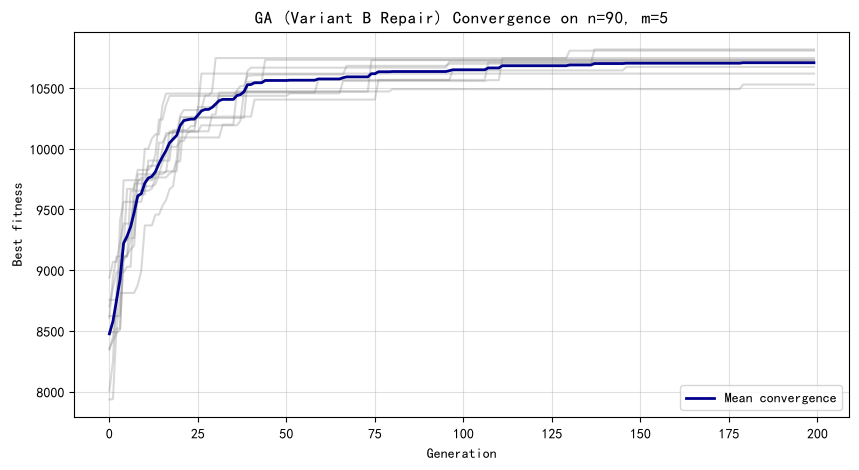

In [8]:
# ========== Part 2: GA for Variant B (Repair) on n=90 ==========

def ga_optimize_repair(n, m, utilities, demands, capacities, pop_size=80, max_iter=200, cross_prob=0.85, mut_prob=0.03, seed=42):
    """
    Genetic Algorithm (GA) with a repair-based constraint handling strategy (Variant B).
    All individuals are guaranteed to be feasible by applying repair_solution.
    """
    random.seed(seed)
    np.random.seed(seed)

    # Initialization: Random binary population followed by immediate repair
    pop = np.random.randint(0, 2, size=(pop_size, n))
    pop = np.array([repair_solution(s, demands, capacities, utilities) for s in pop])

    best_fit = -1
    best_sol = None
    best_fit_hist = []

    for it in range(max_iter):
        # Evaluate fitness for the entire population (returns a tuple, we take the fitness part [0])
        fits = np.array([fitness_repair(s, utilities, demands, capacities)[0] for s in pop])
        
        # Update the global best solution
        current_best_idx = np.argmax(fits)
        if fits[current_best_idx] > best_fit:
            best_fit = fits[current_best_idx]
            best_sol = pop[current_best_idx].copy()
        best_fit_hist.append(best_fit)

        # Selection: Roulette wheel selection based on fitness proportions
        fit_norm = fits - fits.min() + 1e-6
        prob = fit_norm / fit_norm.sum()
        new_pop = []
        for _ in range(pop_size):
            pick_idx = np.random.choice(pop_size, p=prob)
            new_pop.append(pop[pick_idx].copy())
        new_pop = np.array(new_pop)

        # Variation: Single-point crossover + Offspring repair
        for i in range(0, pop_size - 1, 2):
            if np.random.rand() < cross_prob:
                p1 = new_pop[i]; p2 = new_pop[i + 1]
                cut = np.random.randint(1, n - 1)
                c1 = np.concatenate([p1[:cut], p2[cut:]])
                c2 = np.concatenate([p2[:cut], p1[cut:]])
                
                # Ensure offspring remain feasible
                c1 = repair_solution(c1, demands, capacities, utilities)
                c2 = repair_solution(c2, demands, capacities, utilities)
                new_pop[i] = c1; new_pop[i + 1] = c2

        # Variation: Bit reversal mutation + repair
        for i in range(pop_size):
            for j in range(n):
                if np.random.rand() < mut_prob:
                    new_pop[i, j] = 1 - new_pop[i, j]

            # Ensure mutated individual is feasible
            new_pop[i] = repair_solution(new_pop[i], demands, capacities, utilities)

        pop = new_pop

    return best_sol, best_fit, np.array(best_fit_hist)


# --- n=28 sanity check ---
# Validate the GA framework on the small instance before running the large challenge instance
print("==== GA (Variant B) sanity check on n=28 ====")
n28, m28, v28, W28, b28 = load_workload_instance("data/multi_resource_n28_m2.txt")
for seed in range(5):
    sol, fit, hist = ga_optimize_repair(n28, m28, v28, W28, b28, seed=seed)
    print(f"seed={seed}: best_fit={fit:.2f}, n_selected={int(sol.sum())}")

# --- n=90 Single algorithm verification (10 runs) ---
# Evaluate the standalone GA performance on the large instance (Part 2 requirement)
print("\n==== GA (Variant B) on n=90, m=5 (10 runs) ====")
n90, m90, v90, W90, b90 = load_workload_instance("data/multi_resource_n90_m5.txt")

part2_fits = []
part2_hists = []
for run_id in range(10):
    sol, fit, hist = ga_optimize_repair(n90, m90, v90, W90, b90, seed=run_id)
    part2_fits.append(fit)
    part2_hists.append(hist)

# Print statistical summary for the 10 runs
print(f"Mean={np.mean(part2_fits):.2f} Std={np.std(part2_fits):.2f} "
      f"Max={np.max(part2_fits):.2f} Min={np.min(part2_fits):.2f}")

# Plot convergence curve
plt.figure(figsize=(10, 5))
# Plot individual runs (grey lines) to show consistency across different random seeds
for h in part2_hists:
    plt.plot(h, c="gray", alpha=0.3)
    
# Plot the average convergence curve
plt.plot(np.mean(part2_hists, axis=0), c="darkblue", lw=2, label="Mean convergence")
plt.title("GA (Variant B Repair) Convergence on n=90, m=5")
plt.xlabel("Generation")
plt.ylabel("Best fitness")
plt.legend()
plt.grid(alpha=0.4)
plt.show()

### Numerical Results
Here presented two sets of experimental data. 
The first set consists of correctness verification for a small-scale example, testing a total of 5 sets of different random seeds. Each group output the optimal fitness obtained from this search and the number of selected items. It shows that the Variant B-repaired genetic algorithm operates normally on this small-scale problem and is capable of finding feasible solutions.
The second part consists of a large-scale experiment with n=90 and m=5, repeated independently 10 times. The statistical metrics show the mean, standard deviation, maximum, and minimum values. The relatively small standard deviation indicates that the optimal solutions obtained from these 10 experiments differ only slightly, demonstrating that the Variant B algorithm exhibits good result stability for this case. The convergence curve below provides a visual representation of the optimization process across these 10 runs as the number of iterations increases.

### Plot
This figure shows the convergence process of Variant B across 10 independent experiments. Each light gray line in the figure corresponds to the change in optimal fitness for a single run, the dark blue solid line represents the average convergence curve across the 10 experiments.
During the initial 0–50 generations of the iteration, fitness rises rapidly, indicating that the algorithm quickly finds higher-quality solutions. By the middle to late stages of the iteration, the rate of increase on the curve slows noticeably and gradually flattens out, suggesting that the algorithm is gradually converging and finding it difficult to identify further improvements. The fact that the multiple light gray lines cluster closely together also supports the characteristics observed in the previous statistical results: a small standard deviation and good algorithm stability.

## Task3: A vs B

In [9]:
# ========== Part 3: Variant A (Penalty) vs Variant B (Repair) ==========

def make_evaluator(variant, utilities, demands, capacities):
    """
    Factory function to return the appropriate evaluation logic based on the chosen variant.
    - Variant A returns (penalty_fitness, raw_solution)
    - Variant B returns (repair_fitness, repaired_solution) via fitness_repair
    """
    if variant == 'A':
        def evaluate(sol):
            return fitness_penalty(sol, utilities, demands, capacities), sol
        return evaluate
    elif variant == 'B':
        def evaluate(sol):
            return fitness_repair(sol, utilities, demands, capacities)
        return evaluate
    else:
        raise ValueError(f"Unknown variant: {variant}")


def ga_optimize(n, m, utilities, demands, capacities, variant='B',
                pop_size=80, max_iter=200,
                cross_prob=0.85, mut_prob=0.03, seed=42):
    """
    Unified Genetic Algorithm framework for both Variant A (Penalty) and Variant B (Repair).
    Selection, crossover, and mutation operators are identical for both variants to ensure a fair comparison.
    """
    random.seed(seed)
    np.random.seed(seed)
    evaluate = make_evaluator(variant, utilities, demands, capacities)

    # Initialization: Generate random population
    pop = np.random.randint(0, 2, size=(pop_size, n))

    # If Variant B, repair the initial population to ensure all individuals are feasible
    if variant == 'B':
        pop = np.array([repair_solution(s, demands, capacities, utilities) for s in pop])

    best_fit = -np.inf
    best_sol = None
    hist = []

    for it in range(max_iter):
        # Evaluate the entire population using the chosen variant's fitness logic
        results = [evaluate(s) for s in pop]
        fits = np.array([r[0] for r in results], dtype=float)

        # Update the global best solution (only feasible solutions are considered)
        for fit, sol in results:
            if is_feasible(sol, demands, capacities) and fit > best_fit:
                best_fit = float(fit)
                best_sol = sol.copy()
                
        # Record the best fitness for convergence curve (use NaN if no feasible solution found yet)
        hist.append(best_fit if best_fit > -np.inf else np.nan)

        # Selection: Roulette wheel selection
        fit_shift = fits - fits.min() + 1e-6
        prob = fit_shift / fit_shift.sum()
        idx = np.random.choice(pop_size, size=pop_size, p=prob)
        new_pop = pop[idx].copy()

        # Variation: Single-point crossover
        for i in range(0, pop_size - 1, 2):
            if np.random.rand() < cross_prob:
                cut = np.random.randint(1, n)
                c1 = np.concatenate([new_pop[i, :cut], new_pop[i + 1, cut:]])
                c2 = np.concatenate([new_pop[i + 1, :cut], new_pop[i, cut:]])
                # For Variant B, repair the offspring immediately to maintain feasibility
                if variant == 'B':
                    c1 = repair_solution(c1, demands, capacities, utilities)
                    c2 = repair_solution(c2, demands, capacities, utilities)
                new_pop[i], new_pop[i + 1] = c1, c2

        # Variation: Bit flip mutation
        for i in range(pop_size):
            mask = np.random.rand(n) < mut_prob
            if mask.any():
                new_pop[i, mask] = 1 - new_pop[i, mask]
                # For Variant B, repair the mutated individual immediately
                if variant == 'B':
                    new_pop[i] = repair_solution(new_pop[i], demands, capacities, utilities)

        pop = new_pop

    return best_sol, best_fit, np.array(hist, dtype=float)


def run_ga_repeat(n, m, utilities, demands, capacities, variant='B', repeat=30, **ga_kwargs):
    """
    Run the GA multiple times independently and collect statistical results.
    The number of repeats (M=30) satisfies the assignment's requirement for a fair statistical test.
    """
    all_best_fit, all_history = [], []
    for run_id in range(repeat):
        # Use different fixed seeds for each independent run to ensure reproducibility
        sol, fit, hist = ga_optimize(n, m, utilities, demands, capacities, variant=variant, seed=run_id, **ga_kwargs)

        # Replace any infinite values (if no feasible solution was found) with 0.0
        all_best_fit.append(fit if np.isfinite(fit) else 0.0)
        all_history.append(hist)
    return np.array(all_best_fit), np.array(all_history)

## Task3: Run and repeat_times = 30

In [10]:
# --- Run Part 3 (30 runs) ---
# Create a directory to save experimental results (optional but good practice)
os.makedirs("results", exist_ok=True)

# Load Instance 2 (n=90, m=5) for the comparative experiment
n_inst, m_inst, u_inst, D_inst, C_inst = load_workload_instance("data/multi_resource_n90_m5.txt")

# Number of independent runs (satisfies the assignment's requirement of M >= 30)
repeat_times = 30

# ================= Run Variant A (Penalty) =================
t0 = time.time()         # Start timer to measure computational efficiency
resA_fits, resA_hists = run_ga_repeat(n_inst, m_inst, u_inst, D_inst, C_inst, variant='A', repeat=repeat_times)
tA = time.time() - t0    # Calculate elapsed time for Variant A

# Print statistical summary for Variant A
print(f"[Variant A] {repeat_times} runs, elapsed {tA:.1f}s")
print(f"Mean={resA_fits.mean():.2f} Std={resA_fits.std():.2f} "
      f"Max={resA_fits.max():.2f} Min={resA_fits.min():.2f}")

# ================= Run Variant B (Repair) =================
t0 = time.time()         # Start timer for Variant B
resB_fits, resB_hists = run_ga_repeat(n_inst, m_inst, u_inst, D_inst, C_inst, variant='B', repeat=repeat_times)                                     
tB = time.time() - t0    # Calculate elapsed time for Variant B

# Print statistical summary for Variant B
print(f"[Variant B] {repeat_times} runs, elapsed {tB:.1f}s")
print(f"  Mean={resB_fits.mean():.2f} Std={resB_fits.std():.2f} "
      f"Max={resB_fits.max():.2f} Min={resB_fits.min():.2f}")

# ================= Save Results =================
# Save the fitness arrays and convergence histories to .npy files for later visualization and statistical testing
np.save("results/variantA_fits.npy", resA_fits)
np.save("results/variantA_history.npy", resA_hists)
np.save("results/variantB_fits.npy", resB_fits)
np.save("results/variantB_history.npy", resB_hists)

[Variant A] 30 runs, elapsed 38.9s
Mean=8348.77 Std=304.96 Max=9186.00 Min=7833.00
[Variant B] 30 runs, elapsed 146.5s
  Mean=10675.30 Std=82.89 Max=10848.00 Min=10538.00


### Result:
Here are the statistical results from 30 independent runs of the two genetic algorithm variants, Variant A and Variant B.
It can be seen that Variant A has a relatively large standard deviation, indicating significant variation in the results across multiple runs.
Turning to Variant B, a comparison reveals that the mean fitness value obtained by Variant B is significantly higher, indicating better solution quality; at the same time, its standard deviation is much smaller than that of Variant A, suggesting more stable results. However, Variant B takes longer to run because the repair operation adds additional computational overhead during the evolutionary process.

## Task3: Draw plots


Mann-Whitney U = 0.00, p = 3.0180e-11
conclusion：significant difference (α=0.05)
Time: A=38.9s, B=146.5s, ratio=3.77x


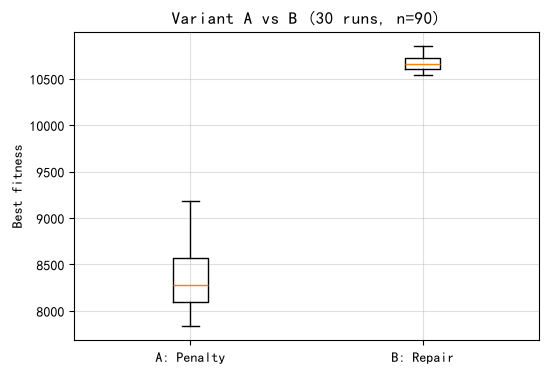

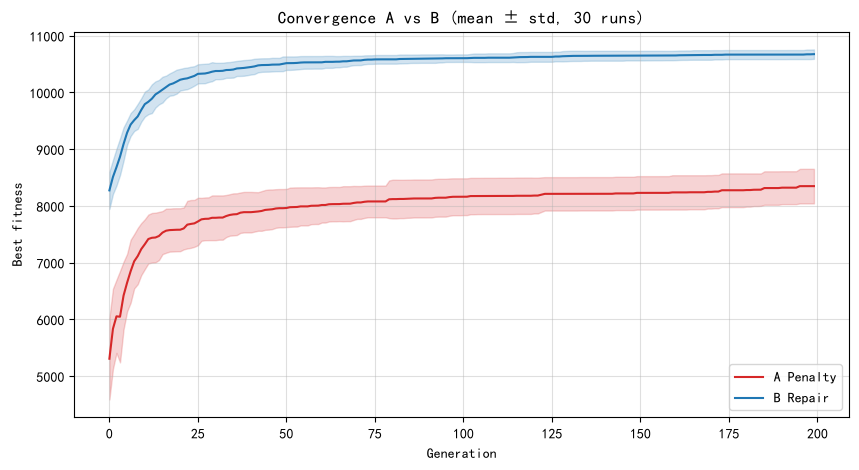

In [11]:
# --- Mann-Whitney U Statistical Test ---
# Perform a non-parametric test to check if the difference in final fitness between A and B is statistically significant
U, p = mannwhitneyu(resA_fits, resB_fits, alternative='two-sided')
print(f"\nMann-Whitney U = {U:.2f}, p = {p:.4e}")
print(f"conclusion：{'significant difference' if p < 0.05 else 'no significant difference'} (α=0.05)")

# Print execution time comparison to analyze the computational trade-off
print(f"Time: A={tA:.1f}s, B={tB:.1f}s, ratio={tB/tA:.2f}x")

# --- Box plots ---
# Boxplot visually displays the median, quartiles, and spread (stability) of the 30 independent runs for both variants
plt.figure(figsize=(6, 4))
plt.boxplot([resA_fits, resB_fits]) 
plt.xticks([1, 2], ['A: Penalty', 'B: Repair'])  
plt.ylabel('Best fitness')
plt.title('Variant A vs B (30 runs, n=90)')
plt.grid(alpha=0.4)
plt.show()

# --- Convergent contrast ---
# Calculate mean and standard deviation across all 30 runs for the convergence curves
mA, sA = np.nanmean(resA_hists, axis=0), np.nanstd(resA_hists, axis=0)
mB, sB = np.nanmean(resB_hists, axis=0), np.nanstd(resB_hists, axis=0)
plt.figure(figsize=(10, 5))

# Plot the mean convergence curve and fill the area (mean ± std) to show variance
for m_, s_, c, l in [(mA, sA, 'tab:red', 'A Penalty'), (mB, sB, 'tab:blue', 'B Repair')]:
    plt.plot(m_, c=c, label=l)
    plt.fill_between(range(len(m_)), m_ - s_, m_ + s_, alpha=0.2, color=c)
    
plt.xlabel('Generation')
plt.ylabel('Best fitness')
plt.title('Convergence A vs B (mean ± std, 30 runs)')
plt.legend()
plt.grid(alpha=0.4)
plt.show()

### Numerical Results
The results of the Mann–Whitney U test show that, at a significance level of α = 0.05, the p-value is significantly less than 0.05, indicating a statistically significant difference between the two groups and that Variant B’s advantage is not due to chance.
The runtime of Variant B is more than three times that of Variant A

### Plot
In the box plots, Variant B exhibits higher overall fitness and narrower boxes, with results from multiple experiments showing greater concentration and less fluctuation; Variant A has a wider data distribution range and unstable performance.

The convergence curves compare the average optimal fitness of the two groups, with the shaded areas representing the standard deviation. The blue B curve remains above the red A curve throughout; it converges faster in the early stages and ultimately stabilizes at a higher fitness platea.  Variant A converges more slowly and ultimately reaches a significantly lower fitness level..

### Conclusion of Task3
1. Variant B (repair strategy) outperforms Variant A (penalty strategy) with higher fitness and more stable results.
2. Variant B converges faster and reaches a better final fitness level.
3. Mann‑Whitney U test (p < 0.05) confirms the performance difference is statistically significant.
4. A downside of Variant B is longer computation time from repeated repair operations.